# Bore Oil Production Forecasting

Compare ARIMA, XGBoost, and LSTM forecasts for well `15/9-F-12`.

**Target:** `BORE_OIL_VOL`  
**Input:** Volve production workbook  
**Evaluation:** chronological train, validation, and test periods

## Notebook Guide

Run cells top to bottom. Set the workbook path in the data-loading section.

## Forecasting Objective

Forecast daily bore oil volume from historical values. The workbook has missing historical dates: ARIMA treats these as unobserved, while lag models count recorded rows.

## Setup and Data

### Imports and Input Path

Set the Volve workbook path and load analysis libraries.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import seaborn as sns
import optuna 


from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler




from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


from xgboost import XGBRegressor
from keras.models import Sequential
from keras.layers import Dense, Input, LSTM
from keras.utils import set_random_seed


import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

set_random_seed(42)




D:\GitHub\.ML_Environment\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load and Select the Production Series

Select well `15/9-F-12` and split its records chronologically (85% train, 15% test).

In [2]:
workbook_path = Path("data/Volve production data.xlsx")

In [3]:
daily_production_data = pd.read_excel(workbook_path, sheet_name="Daily Production Data")


In [4]:
production_only_well_names = (                                    
    daily_production_data.groupby("NPD_WELL_BORE_NAME")["FLOW_KIND"]
    .agg(set)
    .loc[lambda x: x == {"production"}]
)

production_only_well_names

NPD_WELL_BORE_NAME
15/9-F-1 C     {production}
15/9-F-11      {production}
15/9-F-12      {production}
15/9-F-14      {production}
15/9-F-15 D    {production}
Name: FLOW_KIND, dtype: object

In [5]:
production_records = daily_production_data[
    daily_production_data["NPD_WELL_BORE_NAME"].isin(production_only_well_names.index)
]
target_well_data = production_records[
    production_records["NPD_WELL_BORE_NAME"] == "15/9-F-12"
].copy()
target_well_data["DATEPRD"] = pd.to_datetime(
    target_well_data["DATEPRD"], errors="coerce"
)
if target_well_data["DATEPRD"].isna().any():
    raise ValueError("Selected well contains missing or invalid DATEPRD values.")
if target_well_data["DATEPRD"].duplicated().any():
    raise ValueError("Selected well contains duplicate DATEPRD values.")
target_well_data.sort_values("DATEPRD", inplace=True)

In [6]:
train_test_split_index = int(len(target_well_data) * 0.85)

train_df = target_well_data.iloc[:train_test_split_index].copy()
test_df = target_well_data.iloc[train_test_split_index:].copy()

In [7]:
train_df.set_index("DATEPRD", inplace=True)
test_df.set_index("DATEPRD", inplace=True)

In [8]:
test_df.index

DatetimeIndex(['2015-06-17', '2015-06-18', '2015-06-19', '2015-06-20',
               '2015-06-21', '2015-06-22', '2015-06-23', '2015-06-24',
               '2015-06-25', '2015-06-26',
               ...
               '2016-09-08', '2016-09-09', '2016-09-10', '2016-09-11',
               '2016-09-12', '2016-09-13', '2016-09-14', '2016-09-15',
               '2016-09-16', '2016-09-17'],
              dtype='datetime64[ns]', name='DATEPRD', length=459, freq=None)

## Data Inspection and Preparation

Review the selected well, missing values, and production measures before modeling.

In [9]:
train_df.columns

Index(['WELL_BORE_CODE', 'NPD_WELL_BORE_CODE', 'NPD_WELL_BORE_NAME',
       'NPD_FIELD_CODE', 'NPD_FIELD_NAME', 'NPD_FACILITY_CODE',
       'NPD_FACILITY_NAME', 'ON_STREAM_HRS', 'AVG_DOWNHOLE_PRESSURE',
       'AVG_DOWNHOLE_TEMPERATURE', 'AVG_DP_TUBING', 'AVG_ANNULUS_PRESS',
       'AVG_CHOKE_SIZE_P', 'AVG_CHOKE_UOM', 'AVG_WHP_P', 'AVG_WHT_P',
       'DP_CHOKE_SIZE', 'BORE_OIL_VOL', 'BORE_GAS_VOL', 'BORE_WAT_VOL',
       'BORE_WI_VOL', 'FLOW_KIND', 'WELL_TYPE'],
      dtype='object')

In [10]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2597 entries, 2008-02-12 to 2015-06-16
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   WELL_BORE_CODE            2597 non-null   object 
 1   NPD_WELL_BORE_CODE        2597 non-null   int64  
 2   NPD_WELL_BORE_NAME        2597 non-null   object 
 3   NPD_FIELD_CODE            2597 non-null   int64  
 4   NPD_FIELD_NAME            2597 non-null   object 
 5   NPD_FACILITY_CODE         2597 non-null   int64  
 6   NPD_FACILITY_NAME         2597 non-null   object 
 7   ON_STREAM_HRS             2597 non-null   float64
 8   AVG_DOWNHOLE_PRESSURE     2591 non-null   float64
 9   AVG_DOWNHOLE_TEMPERATURE  2591 non-null   float64
 10  AVG_DP_TUBING             2591 non-null   float64
 11  AVG_ANNULUS_PRESS         2584 non-null   float64
 12  AVG_CHOKE_SIZE_P          2553 non-null   float64
 13  AVG_CHOKE_UOM             2597 non-null   obj

In [11]:
train_df["NPD_WELL_BORE_NAME"].value_counts()

NPD_WELL_BORE_NAME
15/9-F-12    2597
Name: count, dtype: int64

In [12]:
train_df["FLOW_KIND"].value_counts()

FLOW_KIND
production    2597
Name: count, dtype: int64

### Inspect the Selected Well

Review training data shape, missingness, and production variables.

In [13]:
train_df.shape

(2597, 23)

In [14]:
train_df.isna().sum()

WELL_BORE_CODE                 0
NPD_WELL_BORE_CODE             0
NPD_WELL_BORE_NAME             0
NPD_FIELD_CODE                 0
NPD_FIELD_NAME                 0
NPD_FACILITY_CODE              0
NPD_FACILITY_NAME              0
ON_STREAM_HRS                  0
AVG_DOWNHOLE_PRESSURE          6
AVG_DOWNHOLE_TEMPERATURE       6
AVG_DP_TUBING                  6
AVG_ANNULUS_PRESS             13
AVG_CHOKE_SIZE_P              44
AVG_CHOKE_UOM                  0
AVG_WHP_P                      0
AVG_WHT_P                      0
DP_CHOKE_SIZE                  0
BORE_OIL_VOL                   0
BORE_GAS_VOL                   0
BORE_WAT_VOL                   0
BORE_WI_VOL                 2597
FLOW_KIND                      0
WELL_TYPE                      0
dtype: int64

### Data Quality and Preparation

Drop the unused water-injection column and impute numeric predictors with training-set medians. Missing target values are rejected rather than fabricated; missing calendar dates are not treated as zero production.

In [15]:
columns_to_drop= ["BORE_WI_VOL"]

In [16]:
train_df.drop(columns_to_drop, axis=1 , inplace=True)
test_df.drop(columns_to_drop, axis=1 , inplace=True)

In [17]:
if "BORE_WI_VOL" in train_df.columns:
    print(f"{columns_to_drop} has been dropped from the DataFrame.")
else:
    print(f"{columns_to_drop} is not present in the DataFrame.")

['BORE_WI_VOL'] is not present in the DataFrame.


In [18]:
train_df["BORE_OIL_VOL"].describe()

count    2597.000000
mean     1710.776534
std      1717.214222
min         0.000000
25%       401.740000
50%       907.190000
75%      2982.630000
max      5901.840000
Name: BORE_OIL_VOL, dtype: float64

### Impute Missing Values

Fit medians only through the training cutoff (2014-07-15); apply them to the later validation and test rows.

In [19]:
def process_data(train_df, test_df, fit_end="2014-07-15"):
    train_df = train_df.copy()
    test_df = test_df.copy()
    for name, frame in (("training", train_df), ("test", test_df)):
        if frame["BORE_OIL_VOL"].isna().any():
            raise ValueError(
                f"{name} target contains missing values; targets must not be imputed."
            )

    numeric_cols = train_df.select_dtypes(include="number").columns.drop(
        "BORE_OIL_VOL", errors="ignore"
    )
    fit_data = train_df.loc[:fit_end, numeric_cols]
    if fit_data.empty:
        raise ValueError("fit_end selects no rows from the training partition.")

    imputer = SimpleImputer(strategy="median")
    imputer.fit(fit_data)
    train_df[numeric_cols] = imputer.transform(train_df[numeric_cols])
    test_df[numeric_cols] = imputer.transform(test_df[numeric_cols])

    return train_df, test_df


In [20]:
train_df, test_df = process_data(train_df, test_df, fit_end="2014-07-15")

## Exploratory Data Analysis

Plot daily production, annual peaks, and the expanding mean.

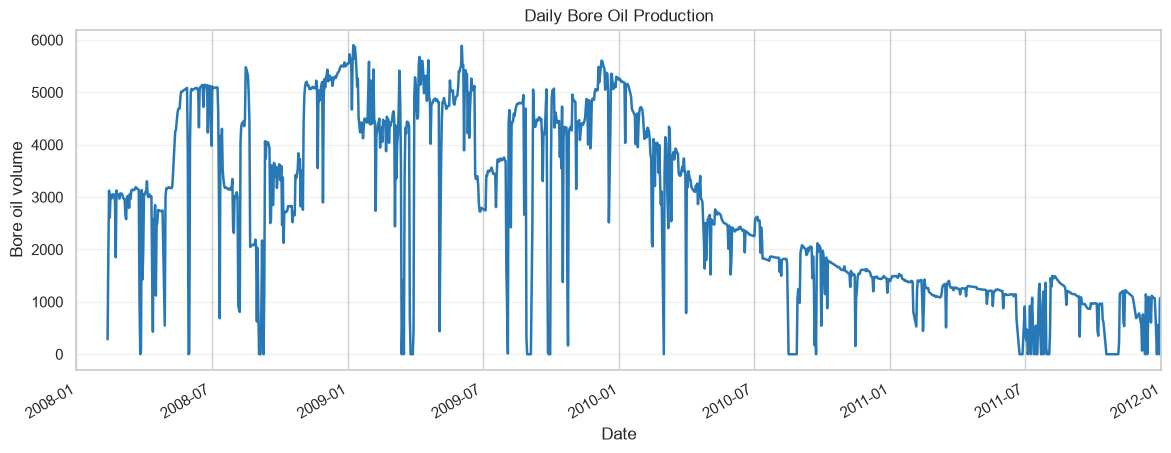

In [21]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].plot(xlim=["2008-01-01", "2012"], figsize=(14, 5), title="Daily Bore Oil Production", color="#2878B5", linewidth=1.8)
ax.set(xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/02_daily_bore_oil_production.png", dpi=300, bbox_inches="tight")
plt.show()


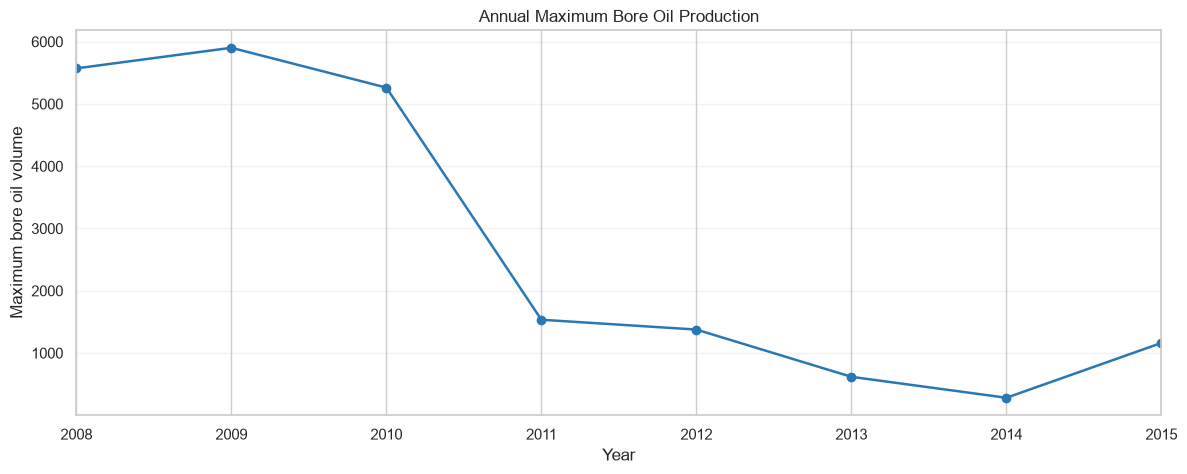

In [22]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].resample(rule="YE").max().plot(figsize=(14, 5), title="Annual Maximum Bore Oil Production", color="#2878B5", linewidth=1.8, marker="o")
ax.set(xlabel="Year", ylabel="Maximum bore oil volume")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/03_annual_maximum_bore_oil_production.png", dpi=300, bbox_inches="tight")
plt.show()


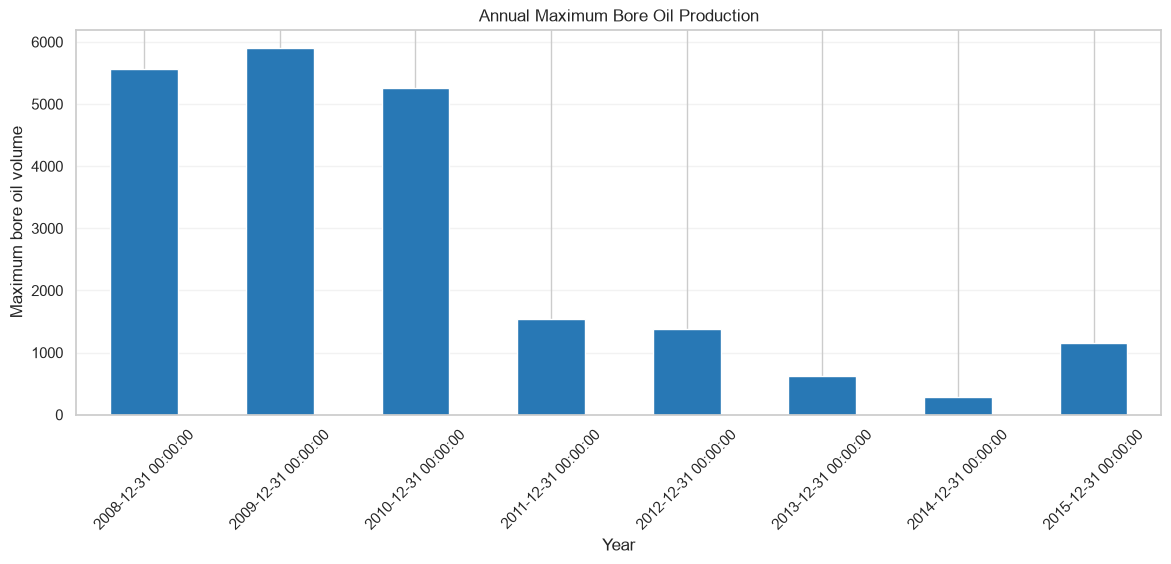

In [23]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].resample(rule="YE").max().plot(kind="bar", figsize=(14, 5), title="Annual Maximum Bore Oil Production", color="#2878B5", edgecolor="white")
ax.set(xlabel="Year", ylabel="Maximum bore oil volume")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/04_annual_maximum_bore_oil_production_bar.png", dpi=300, bbox_inches="tight")
plt.show()


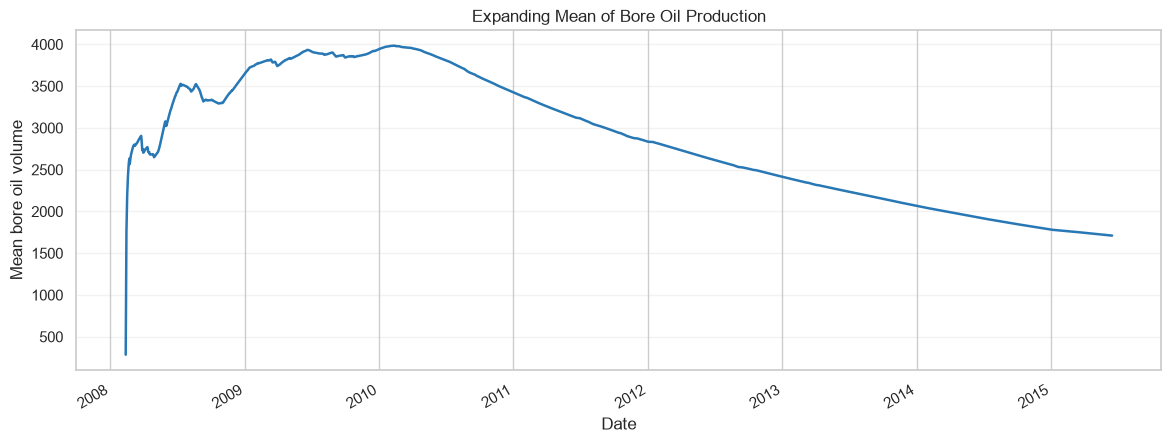

In [24]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].expanding().mean().plot(xlabel="Date", ylabel="Mean bore oil volume", figsize=(14, 5), title="Expanding Mean of Bore Oil Production", color="#2878B5", linewidth=1.8)
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/06_expanding_mean_bore_oil_production.png", dpi=300, bbox_inches="tight")
plt.show()


## Time-Series Diagnostics

Use differencing, the ADF test, decomposition, and autocorrelation plots to inspect stationarity.

### Stationarity Diagnostics

Run daily diagnostics on the contiguous section after the last missing calendar date. The decomposition uses a 7-day period; forecasting still uses the full observed training series.

In [25]:
daily_training_target = train_df["BORE_OIL_VOL"].asfreq("D")
missing_dates = daily_training_target.index[daily_training_target.isna()]
diagnostic_start = (
    missing_dates[-1] + pd.Timedelta(days=1)
    if len(missing_dates)
    else daily_training_target.index[0]
)
diagnostic_df = daily_training_target.loc[diagnostic_start:].to_frame()
if diagnostic_df["BORE_OIL_VOL"].isna().any():
    raise ValueError("Stationarity diagnostics require a contiguous daily segment.")
diagnostic_df["Differenced_BORE_OIL_VOL"] = diagnostic_df["BORE_OIL_VOL"].diff()
diagnostic_df.dropna(subset=["Differenced_BORE_OIL_VOL"], inplace=True)

In [26]:
print(diagnostic_df[["BORE_OIL_VOL", "Differenced_BORE_OIL_VOL"]].head())

            BORE_OIL_VOL  Differenced_BORE_OIL_VOL
DATEPRD                                           
2014-02-09        246.21                    208.89
2014-02-10         25.89                   -220.32
2014-02-11          0.00                    -25.89
2014-02-12        227.19                    227.19
2014-02-13        261.34                     34.15


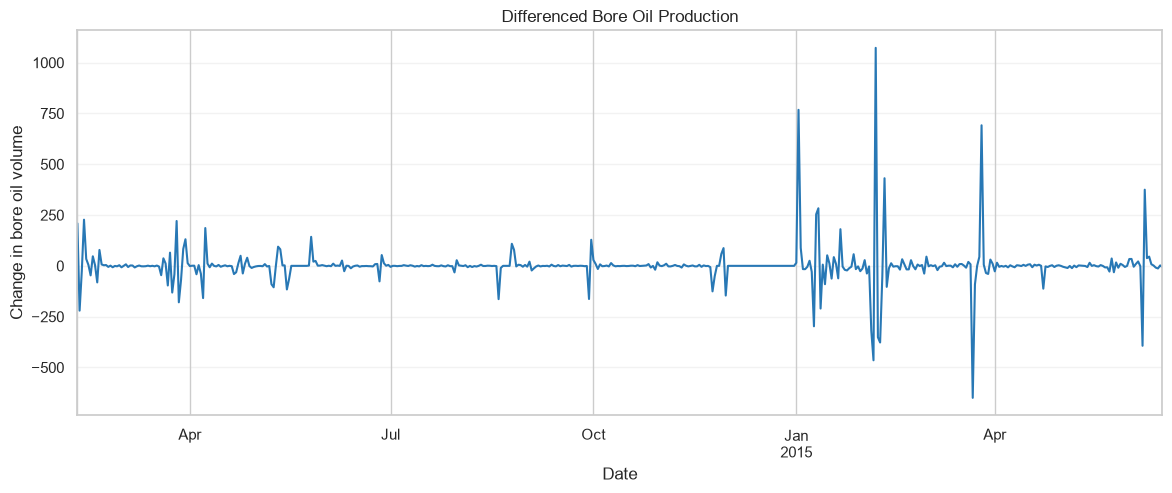

In [27]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = diagnostic_df["Differenced_BORE_OIL_VOL"].plot(figsize=(14, 5), title="Differenced Bore Oil Production", color="#2878B5", linewidth=1.5)
ax.set(xlabel="Date", ylabel="Change in bore oil volume")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/07_differenced_bore_oil_production.png", dpi=300, bbox_inches="tight")
plt.show()


In [28]:
diagnostic_result = sm.tsa.stattools.adfuller(diagnostic_df['Differenced_BORE_OIL_VOL'])
print('ADF Statistic:', diagnostic_result[0])
print('p-value:', diagnostic_result[1])

if diagnostic_result[1] < 0.05:
    print("Data is stationary")
else:
    print("Data is non-stationary")

ADF Statistic: -11.343008907137428
p-value: 1.0433645112227932e-20
Data is stationary


C:\Users\baqee\AppData\Local\Temp\ipykernel_27084\1642144398.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  diagnostic_result = sm.tsa.stattools.adfuller(diagnostic_df['Differenced_BORE_OIL_VOL'])


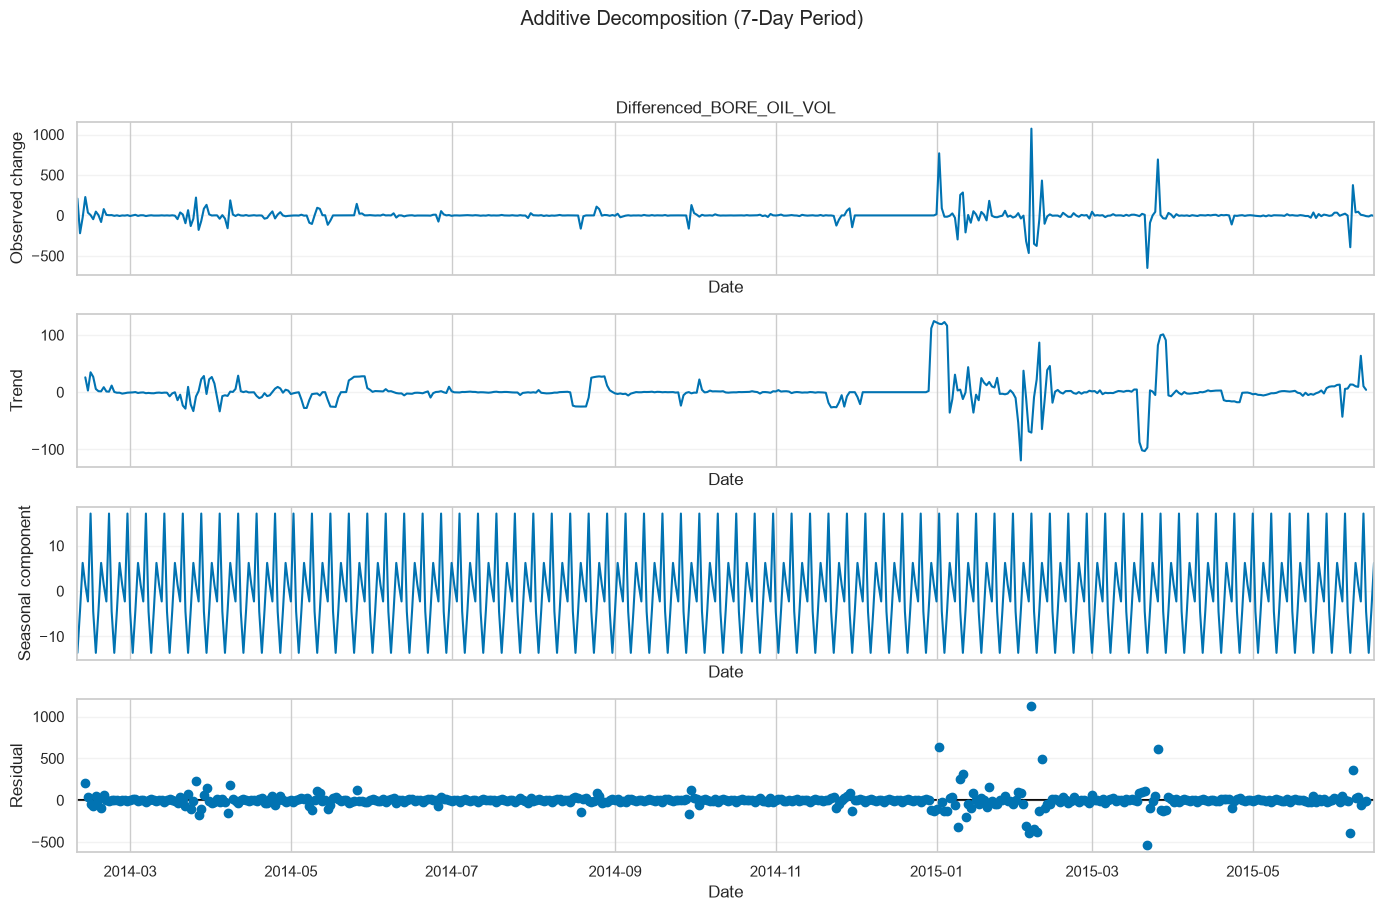

In [29]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
from statsmodels.tsa.seasonal import seasonal_decompose
diagnostic_result = seasonal_decompose(diagnostic_df["Differenced_BORE_OIL_VOL"], model="additive", period=7)
fig = diagnostic_result.plot()
fig.suptitle("Additive Decomposition (7-Day Period)", y=1.01)
fig.set_size_inches(14, 9)
for ax, label in zip(fig.axes, ["Observed change", "Trend", "Seasonal component", "Residual"]):
    ax.set_xlabel("Date")
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout(rect=(0, 0, 1, 0.97))
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/08_seasonal_decomposition.png", dpi=300, bbox_inches="tight")
plt.show()

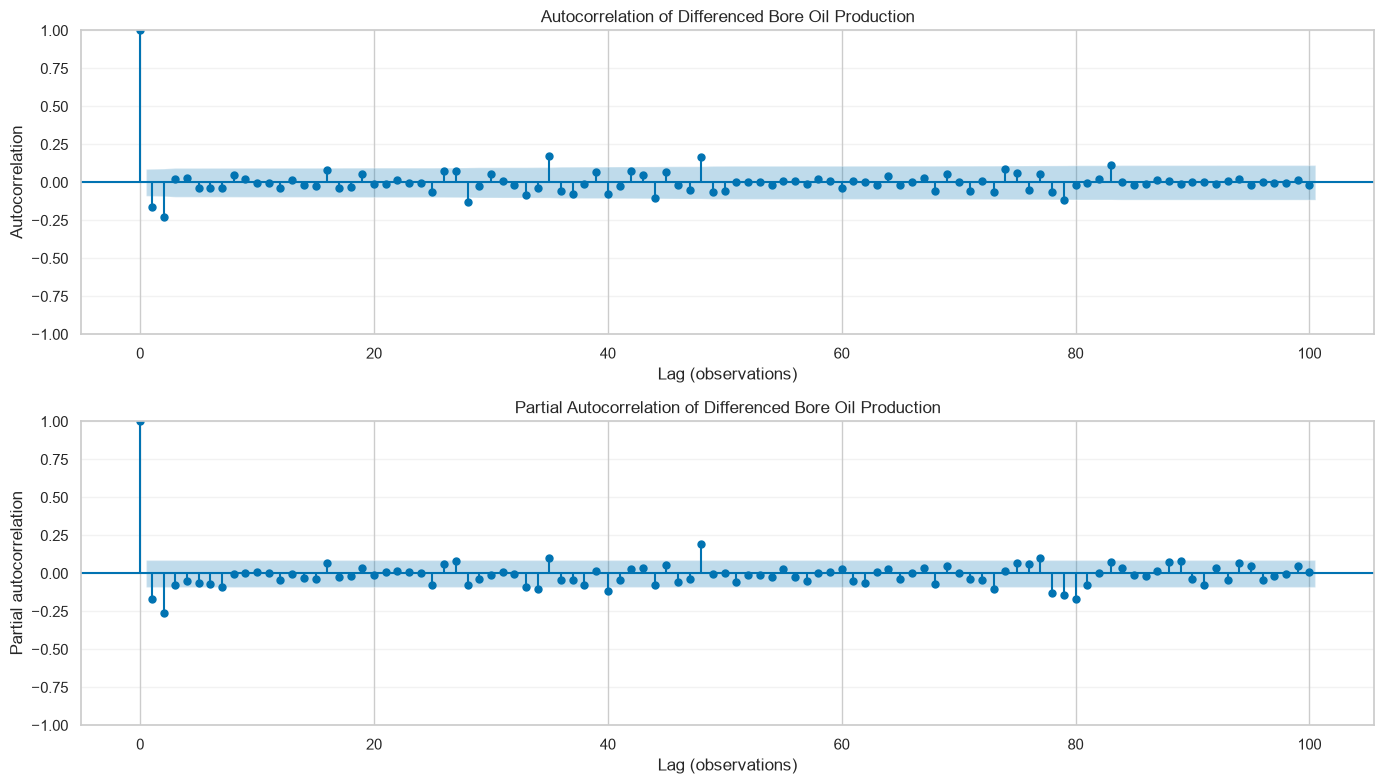

In [30]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
differenced_oil_volume = diagnostic_df["Differenced_BORE_OIL_VOL"].dropna()
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
plot_acf(differenced_oil_volume, lags=100, ax=axes[0], title="Autocorrelation of Differenced Bore Oil Production")
plot_pacf(differenced_oil_volume, lags=100, ax=axes[1], method="ywadjusted", title="Partial Autocorrelation of Differenced Bore Oil Production")
axes[0].set(xlabel="Lag (observations)", ylabel="Autocorrelation")
axes[1].set(xlabel="Lag (observations)", ylabel="Partial autocorrelation")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/09_acf_pacf_differenced_production.png", dpi=300, bbox_inches="tight")
plt.show()

## Forecasting Models

Compare ARIMA, XGBoost, and LSTM.

### ARIMA Baseline

Use ARIMA(3, 1, 2) as a 30-day statistical baseline.

In [31]:
# Preserve calendar time; missing dates stay missing, not zero production.
training_oil_volume = train_df['BORE_OIL_VOL'].asfreq("D")
model = sm.tsa.ARIMA(training_oil_volume, order=(3, 1, 2))
arima_model_fit = model.fit(method_kwargs={"maxiter": 200})
arima_forecast = arima_model_fit.forecast(steps=30)

D:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [32]:
arima_model_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:           BORE_OIL_VOL   No. Observations:                 2682
Model:                 ARIMA(3, 1, 2)   Log Likelihood              -19586.101
Date:                Thu, 22 Oct 2026   AIC                          39184.202
Time:                        20:01:22   BIC                          39219.566
Sample:                    02-12-2008   HQIC                         39196.995
                         - 06-16-2015                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2651      0.009    -29.667      0.000      -0.283      -0.248
ar.L2          0.6946      0.010     68.342      0.000       0.675       0.715
ar.L3         -0.0396      0.010     -3.891      0.000      -0.060      -0.020
ma.L1          0.0558      0.006      9.538      0.000       0.044       0.067
ma.L2         -0.9386      0.006   -156.439      0.000      -0.950      -0.927
sigma2      2.055e+05   1848.975    111.131      0.000    2.02e+05    2.09e+05
===================================================================================
Ljung-Box (L1) (Q):                   1.78   Jarque-Bera (JB):             76784.11
Prob(Q):                              0.18   Prob(JB):                         0.00
Heteroskedasticity (H):               0.02   Skew:                            -1.02
Prob(H) (two-sided):                  0.00   Kurtosis:                        29.14
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

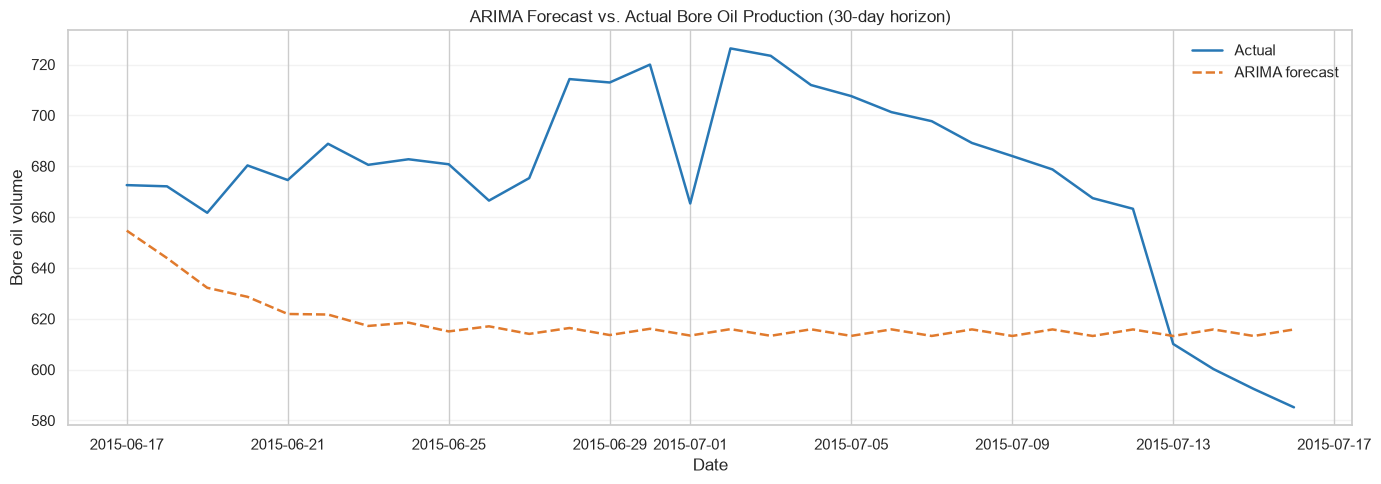

In [33]:
arima_actual = test_df["BORE_OIL_VOL"].reindex(arima_forecast.index).dropna()
arima_forecast = arima_forecast.reindex(arima_actual.index)

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(arima_actual.index, arima_actual, label="Actual", color="#2878B5", linewidth=1.8)
ax.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA forecast",
    color="#E07A2D",
    linewidth=1.8,
    linestyle="--",
)
ax.set(
    title="ARIMA Forecast vs. Actual Bore Oil Production (30-day horizon)",
    xlabel="Date",
    ylabel="Bore oil volume",
)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/10_arima_forecast_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()


In [34]:

arima_residuals = (arima_actual - arima_forecast).rename("Residuals")


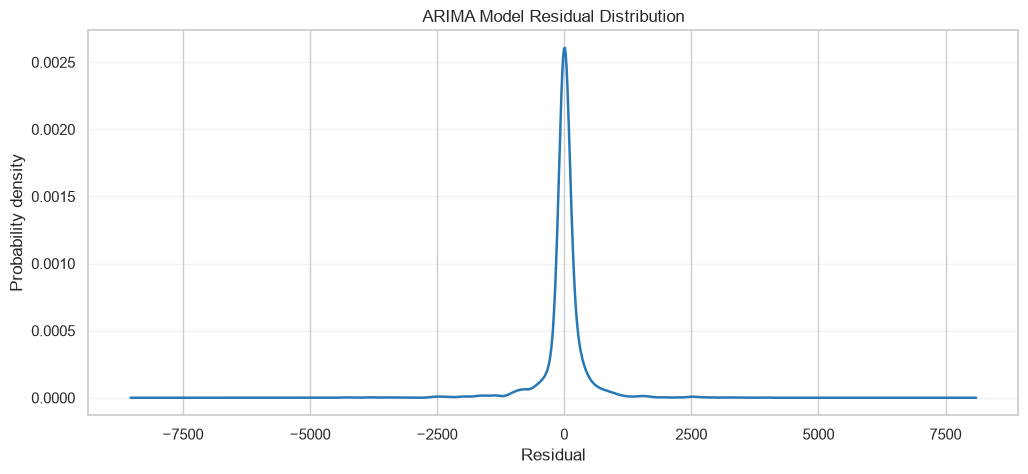

In [35]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = arima_model_fit.resid.plot(kind="kde", figsize=(12, 5), title="ARIMA Model Residual Distribution", color="#2878B5", linewidth=1.8)
ax.set(xlabel="Residual", ylabel="Probability density")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/11_arima_residual_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


### XGBoost Baseline and Optuna-Tuned Model

The fixed-parameter model is a baseline. The source pipeline uses a fixed snapshot from an earlier Optuna run; this notebook performs a seeded search to tune it again.

### Build Lag Features

Create `lag_1` through `lag_30` and define chronological train, validation, and test windows.

In [36]:
def lag_features(df, n=30):
    df= df.copy()
    lag_feature_names=[]
    for i in range(1,n+1):
        df[f"lag_{i}"] = df["BORE_OIL_VOL"].shift(i)
        lag_feature_names.append(f"lag_{i}")

    return df, lag_feature_names

In [37]:
test_history = pd.concat([
    train_df[["BORE_OIL_VOL"]].tail(30),
    test_df[["BORE_OIL_VOL"]],
])
test_with_lags, _ = lag_features(test_history, n=30)
train_df, lag_feature_names = lag_features(train_df, n=30)
test_df = test_df.copy()
test_df[lag_feature_names] = test_with_lags.loc[test_df.index, lag_feature_names]
train_df.dropna(subset=[*lag_feature_names, "BORE_OIL_VOL"], inplace=True)

#### Train and Validation Windows

Train ends 2014-07-15; validation runs 2014-08-16 to 2015-06-16.

In [38]:
x_train = train_df.loc[: "2014-07-15", lag_feature_names]
y_train = train_df.loc[: "2014-07-15", "BORE_OIL_VOL"]

x_val = train_df.loc["2014-08-16":"2015-06-16", lag_feature_names]
y_val = train_df.loc["2014-08-16":"2015-06-16", "BORE_OIL_VOL"]

In [39]:
x_train.loc[:,lag_feature_names].tail(30)

,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,...,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_28,lag_29,lag_30
DATEPRD,,,,,,,,,,,,,,,,,,,,,
2014-06-16,190.81,190.40,193.50,205.41,205.71,205.19,231.66,205.52,205.56,204.19,...,144.14,1.30,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2014-06-17,192.67,190.81,190.40,193.50,205.41,205.71,205.19,231.66,205.52,205.56,...,164.82,144.14,1.30,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2014-06-18,188.43,192.67,190.81,190.40,193.50,205.41,205.71,205.19,231.66,205.52,...,189.10,164.82,144.14,1.30,0.00,0.00,0.00,0.00,0.00,0.00
2014-06-19,187.27,188.43,192.67,190.81,190.40,193.50,205.41,205.71,205.19,231.66,...,190.12,189.10,164.82,144.14,1.30,0.00,0.00,0.00,0.00,0.00
2014-06-20,186.05,187.27,188.43,192.67,190.81,190.40,193.50,205.41,205.71,205.19,...,191.25,190.12,189.10,164.82,144.14,1.30,0.00,0.00,0.00,0.00
2014-06-21,185.52,186.05,187.27,188.43,192.67,190.81,190.40,193.50,205.41,205.71,...,194.94,191.25,190.12,189.10,164.82,144.14,1.30,0.00,0.00,0.00
2014-06-22,184.04,185.52,186.05,187.27,188.43,192.67,190.81,190.40,193.50,205.41,...,196.08,194.94,191.25,190.12,189.10,164.82,144.14,1.30,0.00,0.00
2014-06-23,182.39,184.04,185.52,186.05,187.27,188.43,192.67,190.81,190.40,193.50,...,194.41,196.08,194.94,191.25,190.12,189.10,164.82,144.14,1.30,0.00
2014-06-24,179.37,182.39,184.04,185.52,186.05,187.27,188.43,192.67,190.81,190.40,...,194.94,194.41,196.08,194.94,191.25,190.12,189.10,164.82,144.14,1.30


In [40]:
x_val.loc[:,lag_feature_names].head(30)

,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,...,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_28,lag_29,lag_30
DATEPRD,,,,,,,,,,,,,,,,,,,,,
2014-08-16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,173.47,174.56,180.22,...,186.07,189.06,190.51,188.17,189.90,191.45,191.61,185.94,186.27,187.62
2014-08-17,175.16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,173.47,174.56,...,189.06,186.07,189.06,190.51,188.17,189.90,191.45,191.61,185.94,186.27
2014-08-18,175.23,175.16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,173.47,...,187.63,189.06,186.07,189.06,190.51,188.17,189.90,191.45,191.61,185.94
2014-08-19,174.03,175.23,175.16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,...,186.18,187.63,189.06,186.07,189.06,190.51,188.17,189.90,191.45,191.61
2014-08-20,10.20,174.03,175.23,175.16,175.96,175.42,174.51,175.23,175.91,170.25,...,153.93,186.18,187.63,189.06,186.07,189.06,190.51,188.17,189.90,191.45
2014-08-21,0.00,10.20,174.03,175.23,175.16,175.96,175.42,174.51,175.23,175.91,...,181.66,153.93,186.18,187.63,189.06,186.07,189.06,190.51,188.17,189.90
2014-08-22,0.00,0.00,10.20,174.03,175.23,175.16,175.96,175.42,174.51,175.23,...,183.95,181.66,153.93,186.18,187.63,189.06,186.07,189.06,190.51,188.17
2014-08-23,0.00,0.00,0.00,10.20,174.03,175.23,175.16,175.96,175.42,174.51,...,184.75,183.95,181.66,153.93,186.18,187.63,189.06,186.07,189.06,190.51
2014-08-24,0.00,0.00,0.00,0.00,10.20,174.03,175.23,175.16,175.96,175.42,...,183.88,184.75,183.95,181.66,153.93,186.18,187.63,189.06,186.07,189.06


#### Test Evaluation

The test lags start with the final 30 recorded training observations, then use earlier observed test values for rolling one-step-ahead forecasts. A lag counts records, not guaranteed calendar days.

In [41]:
test_df.dropna(subset=[*lag_feature_names, "BORE_OIL_VOL"], inplace=True)

In [42]:
x_test= test_df[lag_feature_names]
y_test= test_df["BORE_OIL_VOL"]

In [43]:
xgboost_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    objective='reg:squarederror',
    n_jobs=-1,
    random_state=42,
    early_stopping_rounds=50
)

In [44]:
xgboost_model.fit(
    x_train,
    y_train,
    eval_set=[
        (x_train, y_train), 
        (x_val, y_val)
        ],
    verbose=100  
)

[0]	validation_0-rmse:1680.42165	validation_1-rmse:1433.03251


[100]	validation_0-rmse:305.50992	validation_1-rmse:115.38173


[165]	validation_0-rmse:265.15760	validation_1-rmse:115.31945


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [45]:
xgboost_predictions = xgboost_model.predict(x_test)

In [46]:
rmse = np.sqrt(mean_squared_error(y_test, xgboost_predictions))
r2 = r2_score(y_test, xgboost_predictions)
print(f"Root Mean Squared Error: {rmse}")
print(f"R-squared: {r2}")

Root Mean Squared Error: 64.74750824363011
R-squared: 0.8572685172064509


#### Optuna Hyperparameter Search

Select parameters by validation RMSE.

In [47]:
def objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 300, 1500
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.1, log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 2, 10
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 10
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),

        "gamma": trial.suggest_float(
            "gamma", 0, 5
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-8, 10.0, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-8, 10.0, log=True
        ),

        "objective": "reg:squarederror",

        "n_jobs": -1,

        "random_state": 42,

        "early_stopping_rounds": 50
    }

    model = XGBRegressor(**params)

    model.fit(
        x_train,
        y_train,
        eval_set=[(x_val, y_val)],
        verbose=False
    )

    val_pred = model.predict(x_val)

    rmse = np.sqrt(
        mean_squared_error(y_val, val_pred)
    )

    return rmse

In [48]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    direction="minimize",
    study_name="xgb_production_forecasting",
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(
    objective,
    n_trials=100
)

In [49]:
best_params = study.best_params.copy()

best_params.update({
    "objective": "reg:squarederror",
    "n_jobs": -1,
    "random_state": 42,
    "early_stopping_rounds": 50
})

final_model = XGBRegressor(**best_params)

final_model.fit(
    x_train,
    y_train,
    eval_set=[(x_val, y_val)],
    verbose=False
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.9788518822656265
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [50]:
test_pred = final_model.predict(x_test)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_pred)
)

test_r2 = r2_score(y_test, test_pred)
print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test R^2: {test_r2:.2f}")

Test RMSE: 48.66
Test R^2: 0.92


In [51]:
print("Best validation RMSE:", study.best_value)
print("Best parameters:")
print(study.best_params)

print("Train shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Test shape:", x_test.shape)

Best validation RMSE: 94.12138983717205
Best parameters:
{'n_estimators': 406, 'learning_rate': 0.020456448720723976, 'max_depth': 8, 'min_child_weight': 2, 'subsample': 0.898650810844149, 'colsample_bytree': 0.9788518822656265, 'gamma': 3.248994472962045, 'reg_alpha': 3.487302773754967e-08, 'reg_lambda': 0.19543495880575149}
Train shape: (2231, 30)
Validation shape: (305, 30)
Test shape: (459, 30)


In [52]:
Path("models").mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, "models/xgb_production_forecasting_model.pkl")

['models/xgb_production_forecasting_model.pkl']

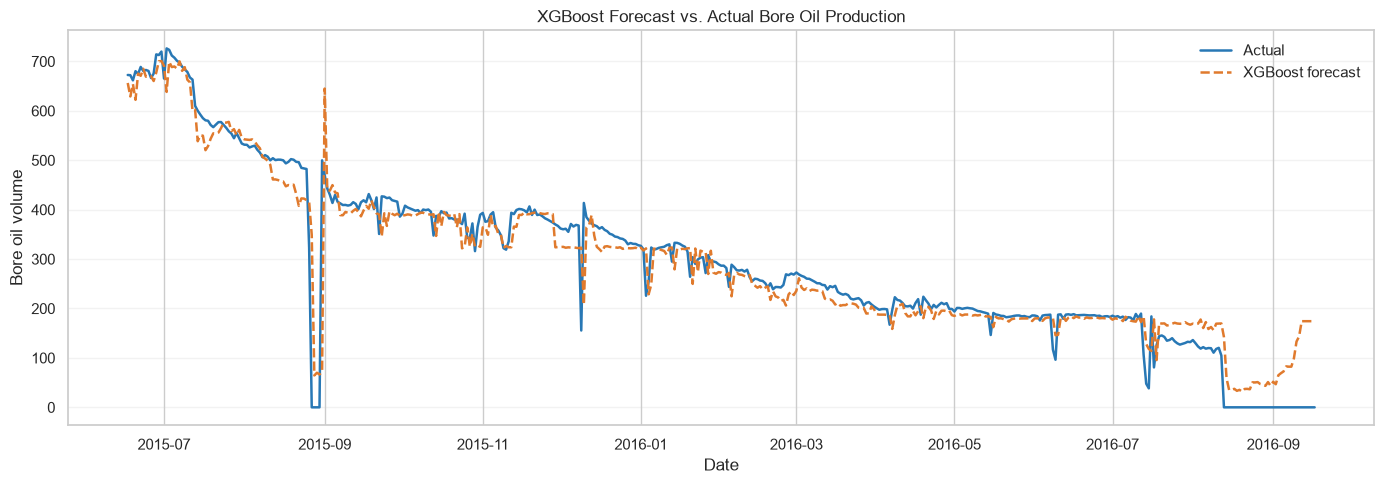

In [53]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_df.index, test_df["BORE_OIL_VOL"], label="Actual", color="#2878B5", linewidth=1.8)
ax.plot(test_df.index, test_pred, label="XGBoost forecast", color="#E07A2D", linewidth=1.8, linestyle="--")
ax.set(title="XGBoost Forecast vs. Actual Bore Oil Production", xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/12_xgboost_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

### LSTM with the Same Lag Windows

Feed lags from oldest to newest, scale using training data, stop on validation loss, and score predictions in original units.

### LSTM Training and Evaluation

Scale lag features, train with validation-based early stopping, then plot test predictions.

In [54]:
lstm_lag_feature_names = list(reversed(lag_feature_names))
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

x_train_scaled = feature_scaler.fit_transform(x_train[lstm_lag_feature_names])
x_val_scaled = feature_scaler.transform(x_val[lstm_lag_feature_names])
x_test_scaled = feature_scaler.transform(x_test[lstm_lag_feature_names])

y_train_scaled = target_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1))
y_val_scaled = target_scaler.transform(y_val.to_numpy().reshape(-1, 1))

x_train_lstm = x_train_scaled.reshape(x_train_scaled.shape[0], len(lag_feature_names), 1)
x_val_lstm = x_val_scaled.reshape(x_val_scaled.shape[0], len(lag_feature_names), 1)
x_test_lstm = x_test_scaled.reshape(x_test_scaled.shape[0], len(lag_feature_names), 1)


In [55]:
from keras.callbacks import EarlyStopping

set_random_seed(42)
lstm_model = Sequential(
    [Input(shape=(len(lag_feature_names), 1)), LSTM(64), Dense(1)]
)

lstm_model.compile(optimizer="adam", loss="mean_squared_error")


In [56]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=45,
    restore_best_weights=True
)

history = lstm_model.fit(
    x_train_lstm,
    y_train_scaled,
    validation_data=(x_val_lstm, y_val_scaled),
    epochs=100,
    batch_size=16,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=0
)


In [57]:
scaled_lstm_predictions = lstm_model.predict(x_test_lstm, verbose=0)
lstm_predictions = target_scaler.inverse_transform(scaled_lstm_predictions).ravel()

lstm_rmse = np.sqrt(mean_squared_error(y_test, lstm_predictions))
lstm_r2 = r2_score(y_test, lstm_predictions)

print(f"Root Mean Squared Error: {lstm_rmse}")
print(f"R-squared: {lstm_r2}")


Root Mean Squared Error: 40.30349708077527
R-squared: 0.9446956719198595


In [58]:
Path("models").mkdir(parents=True, exist_ok=True)
lstm_model.save("models/lstm_production_forecasting_model.keras")
joblib.dump(
    {
        "x_scaler": feature_scaler,
        "y_scaler": target_scaler,
        "lags": lag_feature_names,
        "sequence_lags": lstm_lag_feature_names,
    },
    "models/lstm_production_forecasting_preprocessing.pkl",
)

['models/lstm_production_forecasting_preprocessing.pkl']

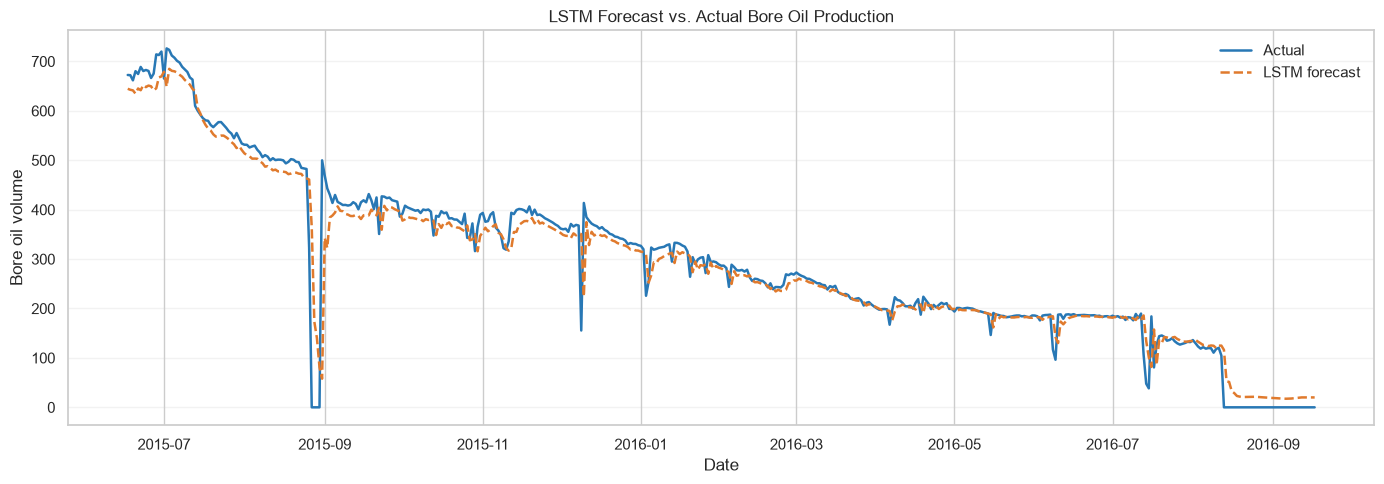

In [59]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test.index, y_test, label="Actual", color="#2878B5", linewidth=1.8)
ax.plot(y_test.index, lstm_predictions, label="LSTM forecast", color="#E07A2D", linewidth=1.8, linestyle="--")
ax.set(title="LSTM Forecast vs. Actual Bore Oil Production", xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/13_lstm_forecast_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()
